<a href="https://colab.research.google.com/github/gibranfp/CursoAprendizajeProfundo/blob/2027-1/notebooks/5c_autocodificadores.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Autocodificadores
En esta libreta programaremos un autocodificador con redes densas usando PyTorch y lo usaremos para reducir a 2 dimensiones tres conjuntos de datos: Iris, vinos y dígitos. En cada caso compararemos la representación que aprende el autocodificador con la que se obtiene con análisis de componentes principales (PCA).

In [1]:
import os

from tqdm.notebook import tqdm

import matplotlib.pyplot as plt
import numpy as np

from sklearn.datasets import load_iris, load_wine, load_digits
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

import torch as th
from torch import nn
from torch.nn import Sequential, Linear, Tanh
from torch.optim import Adam
from torch.utils.data import Dataset, DataLoader

from torch.utils.tensorboard import SummaryWriter

N_EPOCAS = 100
T_LOTE = 10
D_LATENTE = 2
SEED = 42
LR = 1e-3
TBDIR = 'runs/'
DC = th.device('cuda' if th.cuda.is_available() else 'cpu')

# Para reproducibilidad
np.random.seed(SEED)
th.manual_seed(SEED)

## Autocodificador
Un autocodificador está compuesto por un codificador y un decodificador. En esta libreta tanto el codificador como el decodificador serán redes densas.

### Codificador
El codificador proyecta cada entrada $\mathbf{x}$ a un vector latente $\mathbf{z}$ de menor dimensión. Definimos un codificador con dos capas densas ocultas con función de activación tangente hiperbólica y una capa densa de salida lineal.

In [2]:
class Codificador(nn.Module):
  def __init__(self,
               d_ent: int,
               d_ocultas: int,
               d_lat: int) -> None:
    super().__init__()

    self.red_densa = Sequential(Linear(d_ent, d_ocultas),
                                Tanh(),
                                Linear(d_ocultas, d_ocultas),
                                Tanh(),
                                Linear(d_ocultas, d_lat))

  def forward(self,
              x: th.Tensor) -> th.Tensor:
    return self.red_densa(x)

### Decodificador
El decodificador reconstruye la entrada a partir de $\mathbf{z}$ y tiene la estructura inversa. Definimos el decodificador con dos capas densas ocultas con función de activación tangente hiperbólica y una capa de salida lineal (los datos están estandarizados y pueden tomar cualquier valor).

In [3]:
class Decodificador(nn.Module):
  def __init__(self,
               d_sal: int,
               d_ocultas: int,
               d_lat: int) -> None:
    super().__init__()

    self.red_densa = Sequential(Linear(d_lat, d_ocultas),
                                Tanh(),
                                Linear(d_ocultas, d_ocultas),
                                Tanh(),
                                Linear(d_ocultas, d_sal))

  def forward(self,
              z: th.Tensor) -> th.Tensor:
    return self.red_densa(z)

### Clase completa
La clase del autocodificador completo instancia el codificador y el decodificador.

In [4]:
class Autocodificador(nn.Module):
  def __init__(self,
               d_ent: int,
               d_ocultas: int,
               d_lat: int) -> None:
    super().__init__()

    self.cod = Codificador(d_ent, d_ocultas, d_lat)
    self.dec = Decodificador(d_ent, d_ocultas, d_lat)

  def forward(self,
              x: th.Tensor) -> th.Tensor:
    z = self.cod(x)
    return self.dec(z)

Probamos nuestro autocodificador con datos generados aleatoriamente.

In [5]:
ac = Autocodificador(d_ent = 4, d_ocultas = 5, d_lat = 2)
X = th.rand(16, 4)

with th.inference_mode():
  Z = ac.cod(X)
  Xrec = ac(X)

X.shape, Z.shape, Xrec.shape

(torch.Size([16, 4]), torch.Size([16, 2]), torch.Size([16, 4]))

## Conjuntos de datos
Creamos una subclase de `Dataset` para cargar los tres conjuntos de datos que utilizaremos.

In [6]:
class MiDS(Dataset):
  def __init__(self,
               X: np.ndarray) -> None:
    self.x = X

  def __getitem__(self,
                  i: int) -> np.ndarray:
    return self.x[i]

  def __len__(self) -> int:
    return len(self.x)

Para hacer más fácil la generación de los cargadores de datos de los tres conjuntos de datos, definimos una función que toma un arreglo de NumPy y el tamaño de lote, estandariza los datos para que cada atributo tenga media 0 y varianza 1, y crea y regresa el cargador de datos.

In [7]:
def numpy_a_dataloader(X: np.ndarray,
                       t_lote: int) -> tuple[np.ndarray, DataLoader]:
  sc = StandardScaler()
  X = sc.fit_transform(X).astype('float32')

  ds = MiDS(X)
  dl = DataLoader(ds,
                  batch_size = t_lote,
                  shuffle = True)

  x = next(iter(dl))
  print(f'Tamaño del conjunto de datos: {len(ds)}')
  print(f'Forma del lote: {tuple(x.shape)}, tipo: {x.dtype}')

  return X, dl

Probamos nuestra función con datos generados aleatoriamente.

In [8]:
X, dl = numpy_a_dataloader(np.random.rand(16, 4), 2)

Tamaño del conjunto de datos: 16
Forma del lote: (2, 4), tipo: torch.float32


## Funciones para el entrenamiento
Para facilitar el entrenamiento, definimos diversas funciones.

### Registrar información para TensorBoard
Para guardar información que pueda visualizarse con TensorBoard, instanciamos la clase `SummaryWriter` del submódulo `tensorboard` del módulo `utils` y escribimos información mediante los distintos métodos disponibles (por ejemplo, `add_scalar`, `add_image`, `add_histogram`, etc.).

In [9]:
def registra_info_tboard(writer: SummaryWriter,
                         epoca: int,
                         hist: dict[str, np.ndarray]) -> None:
  for (m, v) in hist.items():
    writer.add_scalar(m, v[epoca], epoca)

### Paso de entrenamiento
Definimos una función que realiza un paso de entrenamiento, a la cual llamaremos `paso_ent`. Esta función recibe como argumentos:

* El modelo como una instancia de `Module` (`modelo`).
* La función de pérdida (`fp`).
* Una instancia de `Optimizer` del módulo `optim` de PyTorch para actualizar los pesos y sesgos (`opt`).
* Una instancia de `Tensor` con el lote de entradas (`X`).
* El dispositivo en el que se ejecutará el modelo (`disp`).

En cada paso de entrenamiento, el lote se pasa por el autocodificador para obtener las reconstrucciones, se calcula la pérdida como el error cuadrático medio entre las entradas y sus reconstrucciones, se obtienen los gradientes y se actualizan los parámetros. Si el dispositivo es una GPU que soporta `bfloat16` de forma nativa, usamos precisión mixta.

In [10]:
def paso_ent(modelo: nn.Module,
             fp: nn.Module,
             opt: th.optim.Optimizer,
             X: th.Tensor,
             disp: str | th.device) -> th.Tensor:
  # Ponemos los gradientes asociados a los parámetros
  # a actualizar en cero
  opt.zero_grad()

  tipo_disp = th.device(disp).type

  # Se habilita precisión mixta solo si el dispositivo es cuda y
  # soporta bfloat16 de forma nativa (capacidad de cómputo >= 8.0)
  usa_amp = (tipo_disp == 'cuda' and th.cuda.get_device_capability(disp)[0] >= 8)

  with th.autocast(device_type = tipo_disp,
                   dtype = th.bfloat16, enabled = usa_amp):
    # Propagamos las entradas para obtener las reconstrucciones
    xrec = modelo(X)

    # Calculamos la pérdida
    perdida = fp(xrec, X)

  # Obtenemos los gradientes
  perdida.backward()

  # Actualizamos todos los parámetros del modelo
  opt.step()

  return perdida.detach()

### Época de entrenamiento
Definimos una función para realizar una época de entrenamiento, que llamaremos `entrena_epoca`. Esta función recibe como argumentos:

* El modelo como una instancia de `Module` (`modelo`).
* La función de pérdida (`fp`).
* Una instancia de `Optimizer` del módulo `optim` de PyTorch para actualizar los pesos y sesgos (`opt`).
* El cargador de datos del subconjunto de entrenamiento (`dl`).
* El dispositivo en el que se ejecutará el modelo (`disp`).

Como el último lote puede ser más pequeño que los demás, la pérdida de la época se calcula como el promedio de las pérdidas de los lotes ponderado por su tamaño.

In [11]:
def entrena_epoca(modelo: nn.Module,
                  fp: nn.Module,
                  opt: th.optim.Optimizer,
                  dl: DataLoader,
                  disp: th.device | str = 'cuda') -> float:
  n_total = 0
  suma_perdida = 0.0

  modelo.train()
  for X in dl:
    X = X.to(disp)

    perdida_paso = paso_ent(modelo,
                            fp,
                            opt,
                            X,
                            disp)

    n_lote = X.shape[0]
    n_total += n_lote

    # La pérdida es el promedio sobre los elementos del lote
    suma_perdida += perdida_paso * n_lote

  perdida_epoca = (suma_perdida / n_total).item()
  return perdida_epoca

### Ciclo principal
También definimos el ciclo de entrenamiento principal, que llamaremos `entrena`. Esta función recibe como argumentos:

* El modelo como una instancia de `Module` (`modelo`).
* La función de pérdida (`fp`).
* Una instancia de `Optimizer` del módulo `optim` de PyTorch para actualizar los pesos y sesgos (`opt`).
* El cargador de datos (`dl`).
* El dispositivo en el que se ejecutará el modelo (`disp`).
* El número de épocas de entrenamiento (`n_epocas`).
* La ruta al directorio donde se guardará la información para TensorBoard (`tbdir`).

In [12]:
def entrena(modelo: nn.Module,
            fp: nn.Module,
            opt: th.optim.Optimizer,
            dl: DataLoader,
            disp: th.device | str = 'cuda',
            n_epocas: int = 30,
            tbdir: str = 'runs/') -> tuple[nn.Module, dict[str, np.ndarray]]:

  hist = {
    'perdida': np.zeros(n_epocas)
    }

  tbwriter = SummaryWriter(tbdir)

  modelo.to(disp)
  for e in tqdm(range(n_epocas)):
    hist['perdida'][e] = entrena_epoca(modelo,
                                       fp,
                                       opt,
                                       dl,
                                       disp)

    registra_info_tboard(tbwriter, e, hist)

  print(f'Época {e}: '
        f'Pérdida = {hist["perdida"][e]:.3f}')

  tbwriter.close()

  return modelo, hist

## Funciones para la evaluación
Definimos una función que pasa el modelo a la CPU, lo pone en modo de evaluación y proyecta un arreglo de NumPy con el codificador entrenado.

In [13]:
@th.inference_mode()
def proyecta(modelo: nn.Module,
             X: np.ndarray) -> np.ndarray:
  modelo = modelo.to('cpu')
  modelo.eval()
  return modelo.cod(th.from_numpy(X)).numpy()

También definimos funciones para graficar la pérdida por época y para visualizar los datos proyectados por el codificador junto con los obtenidos con PCA.

In [14]:
def grafica_perdida(hist: dict[str, np.ndarray]) -> None:
  plt.plot(hist['perdida'])
  plt.xlabel('Época')
  plt.ylabel('Pérdida')
  plt.show()

def grafica_proyecciones(Z_ac: np.ndarray,
                         Z_pca: np.ndarray,
                         y: np.ndarray,
                         nombres: list[str]) -> None:
  fig, axs = plt.subplots(1, 2, figsize = (12, 5))

  for ax, Z, titulo in zip(axs,
                           [Z_ac, Z_pca],
                           ['Autocodificador', 'PCA']):
    for k, nombre in enumerate(nombres):
      ax.scatter(Z[y == k, 0],
                 Z[y == k, 1],
                 s = 10,
                 label = nombre)
    ax.set_title(titulo)
    ax.set_xlabel('$z_1$')
    ax.set_ylabel('$z_2$')

  axs[1].legend(loc = 'center left', bbox_to_anchor = (1, 0.5))
  plt.tight_layout()
  plt.show()

## Conjunto de datos de la flor Iris
Cargamos el conjunto de datos Iris usando las funciones predefinidas de scikit-learn. Creamos el cargador de datos con los atributos estandarizados.

In [15]:
iris = load_iris()
Xiris, irisdl = numpy_a_dataloader(iris.data, T_LOTE)

Tamaño del conjunto de datos: 150
Forma del lote: (10, 4), tipo: torch.float32


Instanciamos el autocodificador, la función de pérdida y el optimizador y entrenamos el modelo.

In [16]:
irisac = Autocodificador(d_ent = Xiris.shape[-1],
                         d_ocultas = 10,
                         d_lat = D_LATENTE)

fp = nn.MSELoss()

opt = Adam(irisac.parameters(), lr = LR)

irisac, hist = entrena(irisac,
                       fp,
                       opt,
                       irisdl,
                       disp = DC,
                       n_epocas = N_EPOCAS,
                       tbdir = os.path.join(TBDIR, 'iris'))

  0%|          | 0/100 [00:00<?, ?it/s]

Época 99: Pérdida = 0.047


Graficamos la pérdida por época.

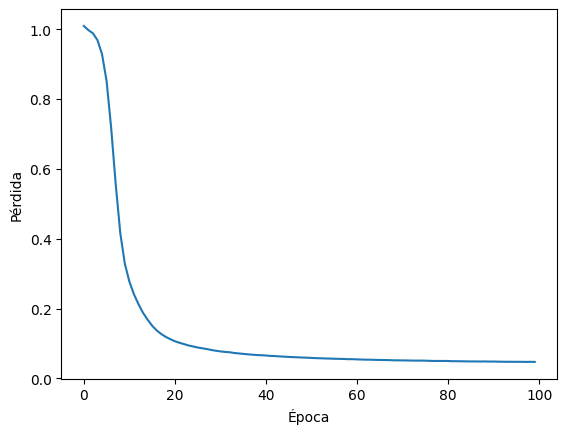

In [17]:
grafica_perdida(hist)

Proyectamos los datos con el codificador entrenado y con PCA y visualizamos ambas proyecciones.

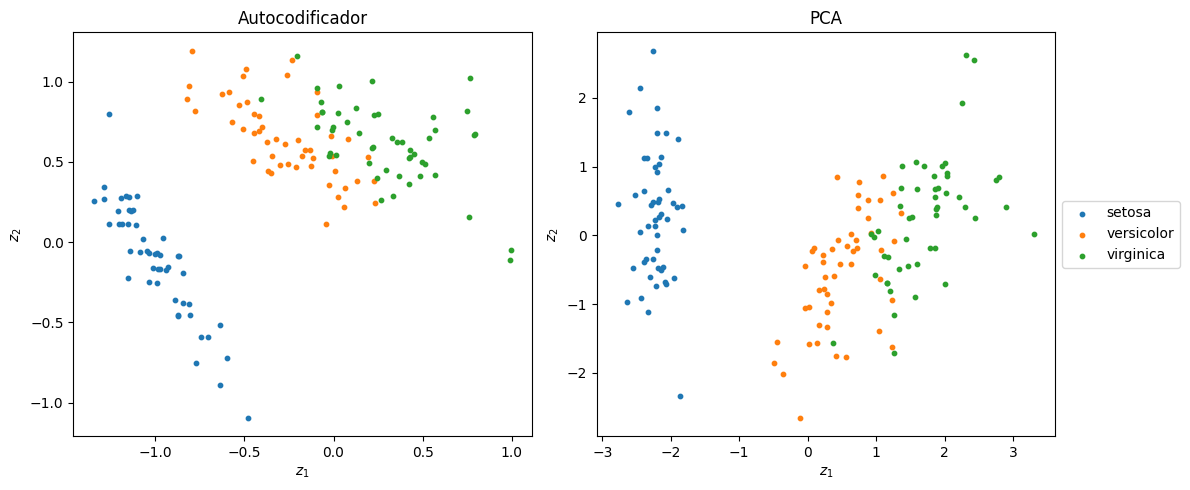

In [18]:
Z_irisac = proyecta(irisac, Xiris)
Z_irispca = PCA(n_components = D_LATENTE).fit_transform(Xiris)
grafica_proyecciones(Z_irisac, Z_irispca, iris.target, list(iris.target_names))

## Conjunto de datos de vinos
Cargamos el conjunto de datos Wine usando las funciones predefinidas de scikit-learn. Creamos el cargador de datos con los atributos estandarizados.

In [19]:
vino = load_wine()
Xvino, vinodl = numpy_a_dataloader(vino.data, T_LOTE)

Tamaño del conjunto de datos: 178
Forma del lote: (10, 13), tipo: torch.float32


Instanciamos y entrenamos el autocodificador.

In [20]:
vinoac = Autocodificador(d_ent = Xvino.shape[-1],
                         d_ocultas = 10,
                         d_lat = D_LATENTE)

fp = nn.MSELoss()

opt = Adam(vinoac.parameters(), lr = LR)

vinoac, hist = entrena(vinoac,
                       fp,
                       opt,
                       vinodl,
                       disp = DC,
                       n_epocas = N_EPOCAS,
                       tbdir = os.path.join(TBDIR, 'vino'))

  0%|          | 0/100 [00:00<?, ?it/s]

Época 99: Pérdida = 0.433


Graficamos la pérdida por época.

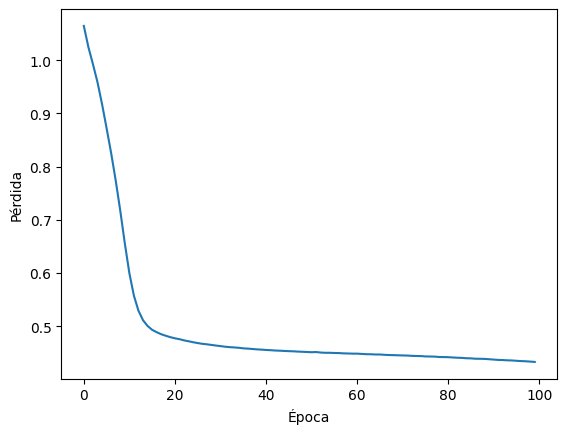

In [21]:
grafica_perdida(hist)

Proyectamos los datos con el codificador entrenado y con PCA y visualizamos ambas proyecciones.

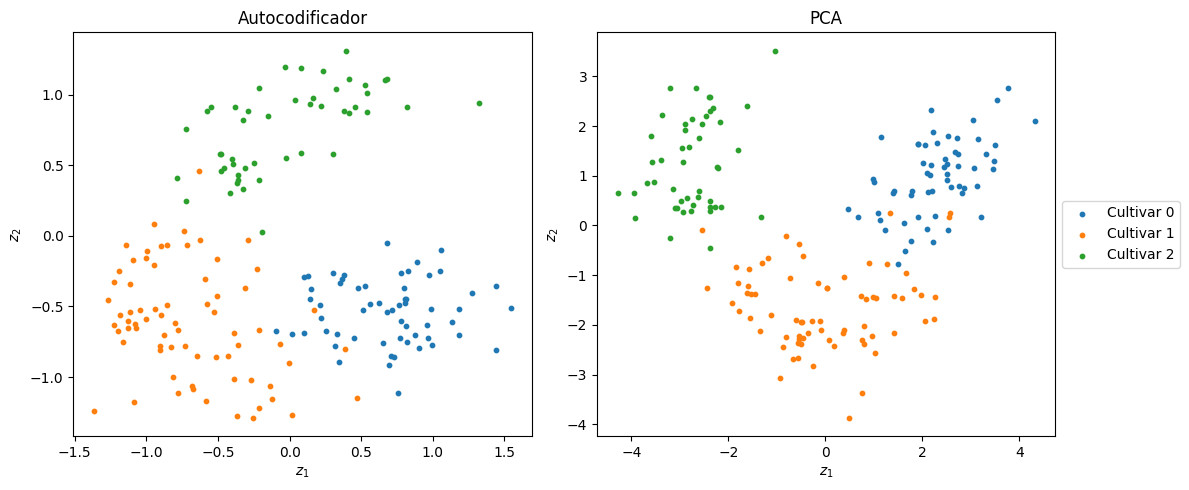

In [22]:
Z_vinoac = proyecta(vinoac, Xvino)
Z_vinopca = PCA(n_components = D_LATENTE).fit_transform(Xvino)
grafica_proyecciones(Z_vinoac, Z_vinopca, vino.target, [f'Cultivar {k}' for k in range(3)])

## Conjunto de datos de dígitos
Cargamos el conjunto de datos Digits usando las funciones predefinidas de scikit-learn. Creamos el cargador de datos con los atributos estandarizados.

In [23]:
digitos = load_digits()
Xdigitos, digitosdl = numpy_a_dataloader(digitos.data, T_LOTE)

Tamaño del conjunto de datos: 1797
Forma del lote: (10, 64), tipo: torch.float32


Instanciamos y entrenamos el autocodificador. Como la entrada tiene más dimensiones que en los conjuntos anteriores, usamos capas ocultas más anchas.

In [24]:
digitosac = Autocodificador(d_ent = Xdigitos.shape[-1],
                            d_ocultas = 64,
                            d_lat = D_LATENTE)

fp = nn.MSELoss()

opt = Adam(digitosac.parameters(), lr = LR)

digitosac, hist = entrena(digitosac,
                          fp,
                          opt,
                          digitosdl,
                          disp = DC,
                          n_epocas = N_EPOCAS,
                          tbdir = os.path.join(TBDIR, 'digitos'))

  0%|          | 0/100 [00:00<?, ?it/s]

Época 99: Pérdida = 0.350


Graficamos la pérdida por época.

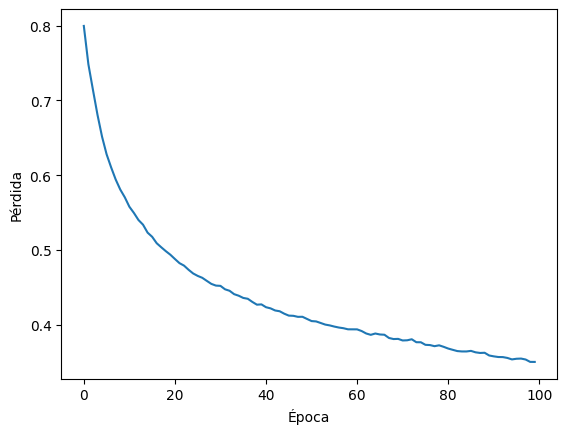

In [25]:
grafica_perdida(hist)

Proyectamos los datos con el codificador entrenado y con PCA y visualizamos ambas proyecciones.

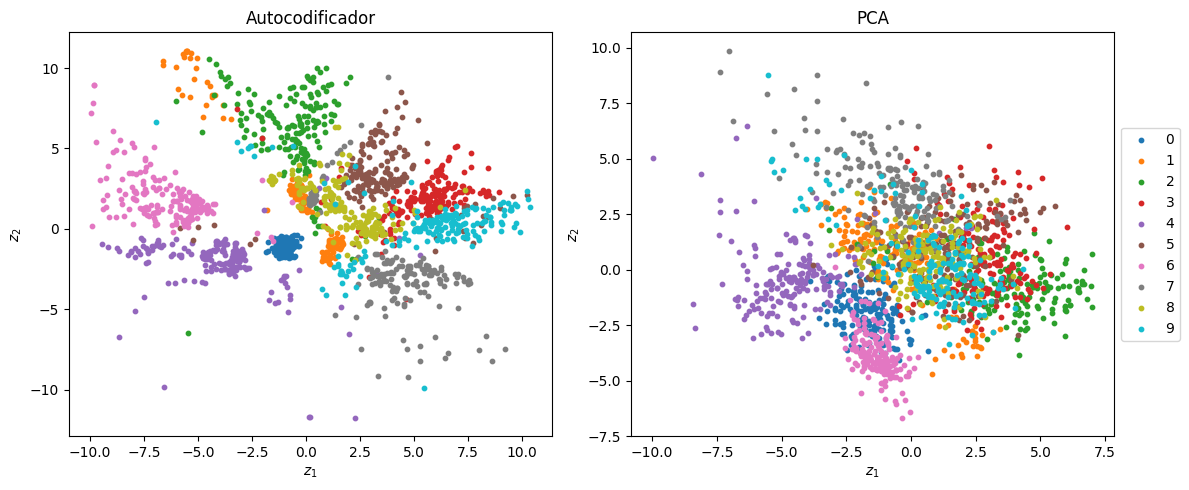

In [26]:
Z_digitosac = proyecta(digitosac, Xdigitos)
Z_digitospca = PCA(n_components = D_LATENTE).fit_transform(Xdigitos)
grafica_proyecciones(Z_digitosac, Z_digitospca, digitos.target, [str(k) for k in range(10)])